# Phase 0: synthetic baseline scorecard

Companion to `README.md`. Regenerates every figure from `data/` (a copy of `runs/synth200_s0_baseline/`). Cells under *Failure examples* re-run the pipeline on 3 stars (~20 s).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-13_phase0-synthetic-baseline"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


In [2]:
sys.path.insert(0, str(REPO / 'benchmarks'))
import scorecard
per_star = pd.read_csv(DATA / 'per_star.csv')
per_method = pd.read_csv(DATA / 'per_method.csv')
metrics = json.loads((DATA / 'metrics.json').read_text())
BINS = list(ev.PERIOD_BIN_LABELS)
print(len(per_star), 'stars;', metrics['config']['dataset'], 'commit', metrics['config']['git_commit'])

200 stars; synthetic:n=200,seed=0 commit a5fa572-dirty


## Figures 1–3: standard scorecard figures
These are exactly what `scorecard.py` writes for every run.

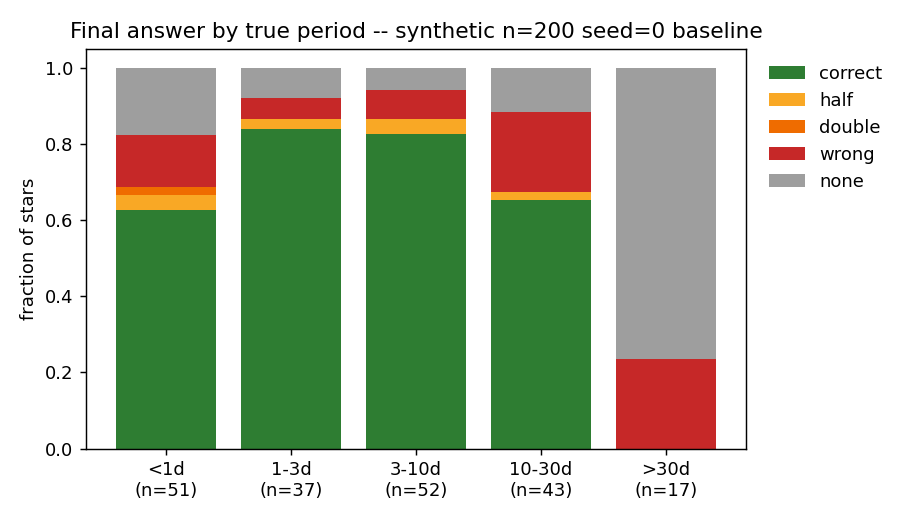

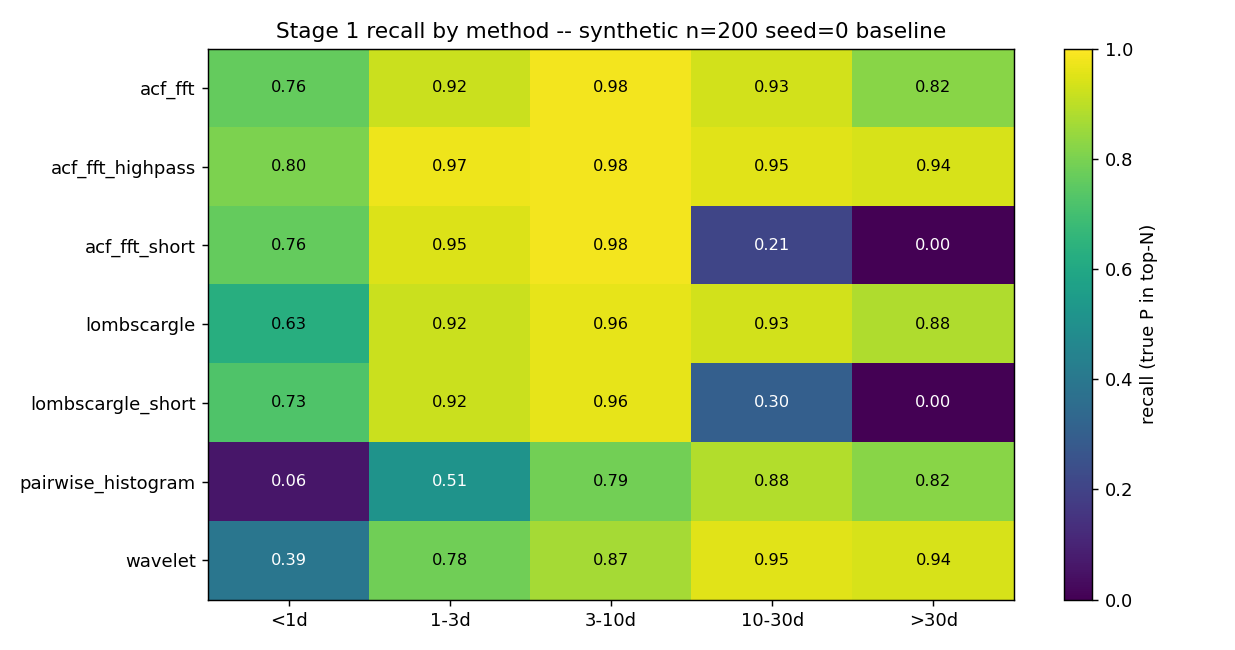

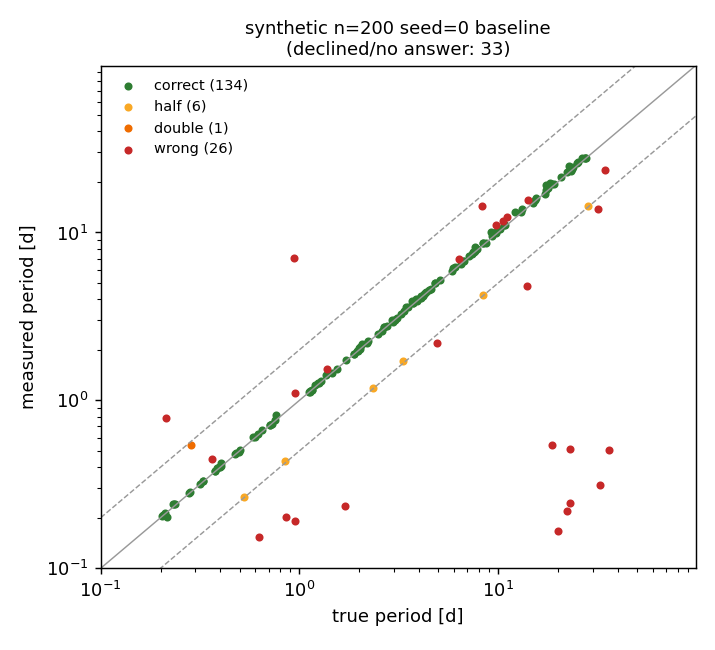

In [3]:
scorecard.make_figures(per_star, per_method, FIG, 'synthetic n=200 seed=0 baseline')
from IPython.display import Image, display
for f in ['fig_final_outcomes_by_bin.png', 'fig_method_recall_by_bin.png', 'fig_measured_vs_true.png']:
    display(Image(FIG / f))

## Figure 4: the arbitration gap
For each period bin: the fraction of stars where *any* Stage-1 method put the true period in its candidate list (an upper bound on what Stage 2 could achieve with these candidates), next to the fraction where Stage 2 actually picked it. Note Stage 2 only fits candidates from the 3 default methods, so the pool-restricted recall (middle bar) is the fairer ceiling.

In [4]:
default = scorecard.DEFAULT_PIPELINE_METHODS
hit = per_method.assign(hit=per_method.outcome == ev.CORRECT)
union_all = hit.groupby(['star_id', 'period_bin']).hit.any().groupby('period_bin').mean()
union_def = hit[hit.method.isin(default)].groupby(['star_id', 'period_bin']).hit.any().groupby('period_bin').mean()
final = per_star.assign(c=per_star.final_outcome == ev.CORRECT).groupby('period_bin').c.mean()
gap = pd.DataFrame({'any method (all 7)': union_all, 'any default method (pool fit)': union_def, 'final answer': final}).reindex(BINS)
display(gap.round(2))
ax = gap.plot.bar(figsize=(7.5, 4), color=['#90caf9', '#1e88e5', '#2e7d32'], rot=0)
ax.set_ylabel('fraction of stars with true P'); ax.set_ylim(0, 1.05)
ax.set_title('Stage 1 finds it, Stage 2 often does not pick it')
ax.legend(frameon=False, loc='lower left'); plt.tight_layout(); plt.savefig(FIG / 'fig_arbitration_gap.png', dpi=130); plt.show()

,any method (all 7),any default method (pool fit),final answer
period_bin,,,
<1d,0.84,0.78,0.63
1-3d,0.97,0.92,0.84
3-10d,0.98,0.98,0.83
10-30d,0.95,0.95,0.65
>30d,0.94,0.94,0.00


/var/folders/kk/_9cq7r5j5nd8cxryt5p59v2c0000gn/T/ipykernel_38088/1543255510.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.legend(frameon=False, loc='lower left'); plt.tight_layout(); plt.savefig(FIG / 'fig_arbitration_gap.png', dpi=130); plt.show()


## Figure 5: what the wrong answers are
Ratio of measured to true period for every `wrong` final answer. Clusters at simple ratios would point at harmonic confusion beyond the P/2, 2P alias categories.

In [5]:
w = per_star[per_star.final_outcome == ev.WRONG]
ratio = w.final_period / w.true_period
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(ratio), bins=40, color='#c62828')
for r, lab in [(1/3, '1/3'), (1/2, '1/2'), (1, '1'), (2, '2'), (3, '3')]:
    ax.axvline(np.log10(r), color='0.5', ls=':'); ax.text(np.log10(r), ax.get_ylim()[1]*0.9, lab, ha='center')
ax.set_xlabel('log10(measured / true)'); ax.set_ylabel('stars'); ax.set_title(f'Wrong final answers (n={len(w)})')
plt.tight_layout(); plt.savefig(FIG / 'fig_wrong_ratio.png', dpi=130); plt.show()
print(w.groupby('period_bin').size().reindex(BINS).fillna(0).astype(int).to_dict())

{'<1d': 7, '1-3d': 2, '3-10d': 4, '10-30d': 9, '>30d': 4}


/var/folders/kk/_9cq7r5j5nd8cxryt5p59v2c0000gn/T/ipykernel_38088/378874046.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(FIG / 'fig_wrong_ratio.png', dpi=130); plt.show()


## Figure 6: failure examples
Three 10–30 d stars where the default candidate pool contained the true period but Stage 2 chose something else. Top: light curve. Bottom: ACF with true P (green dashed, plus multiples) and the selected P (red).

In [6]:
import warnings; warnings.simplefilter('ignore')
from synthetic import make_suite
from acf_utils import compute_acf
from guesses import gather_initial_guesses
from comb_fit import fit_rotation_period
suite = {lc.star_id: lc for lc in make_suite(200, seed=0)}
had = hit[hit.method.isin(default)].groupby('star_id').hit.any()
ex = per_star[(per_star.period_bin == '10-30d') & (per_star.final_outcome == ev.WRONG) & per_star.star_id.map(had)].head(3)
fig, axes = plt.subplots(2, len(ex), figsize=(5 * len(ex), 6), squeeze=False)
for j, (_, r) in enumerate(ex.iterrows()):
    lc = suite[r.star_id]; lags, acf = compute_acf(lc.time, lc.flux)
    g, _ = gather_initial_guesses(lc.time, lc.flux, lags, acf, n_guesses=10)
    res = fit_rotation_period(lags, acf, g)
    axes[0, j].plot(lc.time, lc.flux, ',k'); axes[0, j].set_title(f"{r.star_id}\nP_true={r.true_period:.2f}  chosen={r.final_period:.2f}  SNR={r.meta_snr:.1f}", fontsize=9)
    axes[1, j].plot(lags, acf, 'k', lw=0.8)
    for k in range(1, int(lags[-1] / r.true_period) + 1): axes[1, j].axvline(k * r.true_period, color='g', ls='--', lw=0.8)
    axes[1, j].axvline(r.final_period, color='r', lw=1.5)
    gate = [(round(c.period, 2), c.passed_gates) for c in res.candidates[:6]]
    axes[1, j].set_xlabel('lag [d]'); axes[1, j].set_title(f'top fitted cands (P, passed): {gate}', fontsize=7)
plt.tight_layout(); plt.savefig(FIG / 'fig_failure_examples.png', dpi=110); plt.show()